# Phase 4 · 2/3 — Prévision du KPI par Deep Learning (LSTM / RNN)

**VIGIE · Groupe BI 5** — Raed Meddeb · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Projet Intégré, ESPRIT School of Business · Tuteurs : Aymen Ben Brik et Hela Hammami

---

**Question posée.** Un réseau récurrent prévoit-il mieux le nombre de clôtures de la semaine suivante qu'une
règle simple ?

| Étape | Contenu |
|---|---|
| 1 | Protocole : découpage chronologique, fenêtres glissantes, normalisation |
| 2 | Modèles de référence : naïve, moyenne mobile, médiane mobile, ARIMA |
| 3 | LSTM et RNN simple |
| 4 | Comparaison sur les 40 dernières semaines (MAE, RMSE) |
| 5 | Analyse des erreurs |
| 6 | Prévision des 8 prochaines semaines |
| 7 | Bonus : un second KPI |

Le code des modèles est dans `04_machine_learning/src/prevision.py` ; ce notebook l'exécute et commente les résultats.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
sys.path.insert(0, str(RACINE / "04_machine_learning" / "src"))
import prevision
from vigie import config, donnees, series, style

warnings.filterwarnings("ignore")
style.appliquer()
C = config.COULEURS
fr = style.milliers

# La série est reconstruite depuis les données (et non relue d'un fichier) : le notebook est autonome.
df = donnees.charger()
comptes = donnees.grain_compte(df)
brute = series.serie_hebdo(comptes.loc[comptes["CHURN"] == 1, "ACCT_CLOSE_DATE"])
masse = series.semaines_de_masse(brute)
serie = series.corriger_masse(brute, masse)
valeurs = serie.to_numpy(dtype=float)
print(f"{len(serie)} semaines, du {serie.index[0]:%d/%m/%Y} au {serie.index[-1]:%d/%m/%Y} — {len(masse)} semaines de masse corrigées")

202 semaines, du 13/04/2020 au 19/02/2024 — 5 semaines de masse corrigées


## 1. Protocole d'évaluation

### 1.1 Découpage chronologique

Aucun mélange aléatoire : le modèle est entraîné sur le passé et évalué sur le futur.

,Rôle,Début,Fin,Semaines,Part
Entraînement,Apprentissage des poids,13/04/2020,26/12/2022,142,70%
Validation,Arrêt précoce de l'entraînement,02/01/2023,15/05/2023,20,10%
Test,Évaluation finale (jamais vue),22/05/2023,19/02/2024,40,20%


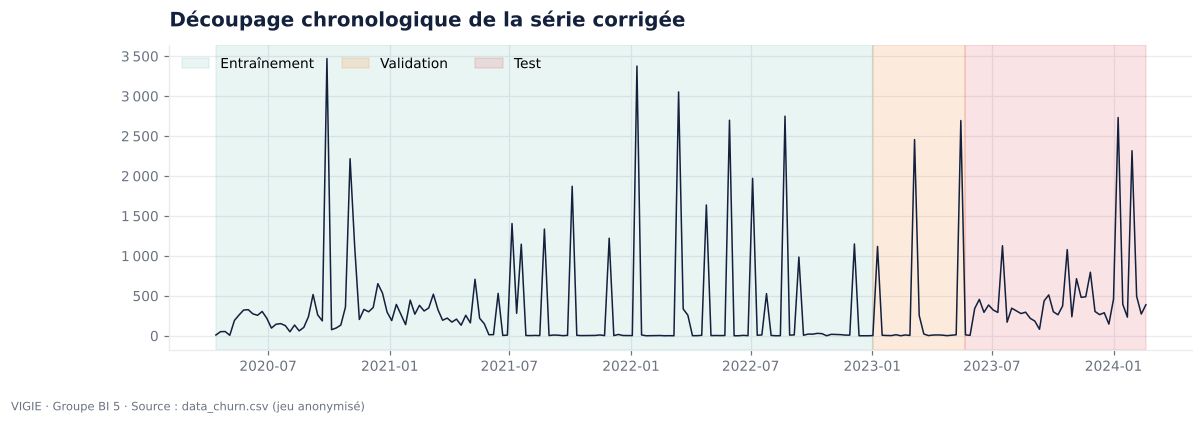

In [2]:
dec = prevision.Decoupage.construire(valeurs)
plan = pd.DataFrame({
    "Rôle": ["Apprentissage des poids", "Arrêt précoce de l'entraînement", "Évaluation finale (jamais vue)"],
    "Début": [serie.index[0], serie.index[dec.fin_train], serie.index[dec.fin_validation]],
    "Fin": [serie.index[dec.fin_train - 1], serie.index[dec.fin_validation - 1], serie.index[-1]],
    "Semaines": [dec.fin_train, prevision.TAILLE_VALIDATION, prevision.TAILLE_TEST],
}, index=["Entraînement", "Validation", "Test"])
plan["Part"] = (plan["Semaines"] / dec.n).map("{:.0%}".format)
plan["Début"] = plan["Début"].dt.strftime("%d/%m/%Y")
plan["Fin"] = plan["Fin"].dt.strftime("%d/%m/%Y")
display(plan)

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(serie.index, serie.values, color=C["encre"], lw=1)
ax.axvspan(serie.index[0], serie.index[dec.fin_train], color=C["retention"], alpha=0.10, label="Entraînement")
ax.axvspan(serie.index[dec.fin_train], serie.index[dec.fin_validation], color=C["ambre"], alpha=0.22, label="Validation")
ax.axvspan(serie.index[dec.fin_validation], serie.index[-1], color=C["churn"], alpha=0.13, label="Test")
ax.yaxis.set_major_formatter(style.milliers)
ax.set_title("Découpage chronologique de la série corrigée")
ax.legend(loc="upper left", ncol=3)
style.enregistrer(fig, "04_decoupage_temporel")
plt.show()

### 1.2 Transformation et normalisation — sans fuite d'information

1. `log(1 + x)` : ramène les pics à une échelle comparable au reste (le `+ 1` gère les semaines à zéro).
2. Centrage-réduction avec la moyenne et l'écart-type **calculés sur l'entraînement uniquement**.
   Utiliser les statistiques de toute la série ferait entrer de l'information du futur dans le modèle.

In [3]:
print(f"Paramètres de normalisation, calculés sur les {dec.fin_train} semaines d'entraînement :")
print(f"   moyenne de log(1 + x) = {dec.moyenne:.3f}   |   écart-type = {dec.ecart_type:.3f}")
z_test = dec.normaliser(valeurs[dec.fin_validation:])
print(f"Contrôle : sur le test, la série normalisée a pour moyenne {z_test.mean():+.2f} (≠ 0, comme attendu : "
      f"le test n'a pas servi au calcul).")

Paramètres de normalisation, calculés sur les 142 semaines d'entraînement :
   moyenne de log(1 + x) = 3.803   |   écart-type = 2.387
Contrôle : sur le test, la série normalisée a pour moyenne +0.82 (≠ 0, comme attendu : le test n'a pas servi au calcul).


### 1.3 Fenêtres glissantes

Le réseau reçoit les **8 dernières semaines** et doit prévoir **la suivante**. La fenêtre glisse d'une semaine à la fois.

In [4]:
X, y = series.fenetres(dec.normaliser(valeurs), prevision.FENETRE)
cible = np.arange(prevision.FENETRE, dec.n)
repartition = pd.Series({
    "Fenêtres d'entraînement": int((cible < dec.fin_train).sum()),
    "Fenêtres de validation": int(((cible >= dec.fin_train) & (cible < dec.fin_validation)).sum()),
    "Fenêtres de test": int((cible >= dec.fin_validation).sum()),
}, name="Nombre")
display(repartition.to_frame())
print(f"Forme de X : {X.shape}  →  (fenêtres, {prevision.FENETRE} semaines)   |   Forme de y : {y.shape}")
print("Une fenêtre de test contient des semaines antérieures au test : c'est normal, ce sont des valeurs déjà "
      "observées au moment de la prévision.")

,Nombre
Fenêtres d'entraînement,134
Fenêtres de validation,20
Fenêtres de test,40


Forme de X : (194, 8)  →  (fenêtres, 8 semaines)   |   Forme de y : (194,)
Une fenêtre de test contient des semaines antérieures au test : c'est normal, ce sont des valeurs déjà observées au moment de la prévision.


**Prévision « à un pas ».** Pour chaque semaine du test, tous les modèles — réseaux et références — prévoient à
partir des valeurs réellement observées jusqu'à la semaine précédente. C'est le fonctionnement opérationnel :
chaque lundi, on prévoit la semaine qui commence.

## 2. Modèles de référence

Un réseau de neurones ne vaut que s'il bat des règles qui tiennent en une ligne.

| Référence | Prévision pour la semaine *t* |
|---|---|
| **Naïve** | la valeur de la semaine *t − 1* |
| **Moyenne mobile 4** | la moyenne des 4 dernières semaines |
| **Médiane mobile 8** | la médiane des 8 dernières semaines — robuste aux pics |
| **ARIMA** | modèle statistique classique sur `log(1 + x)`, ordre choisi par AIC sur la période avant le test |

In [5]:
resultat = prevision.evaluer_kpi(serie)        # entraîne aussi les réseaux (≈ 1 minute)
modele_lstm = resultat.pop("_modele_lstm")
comparaison = pd.DataFrame(resultat["comparaison"]).set_index("Modèle")
print("Ordre ARIMA retenu par AIC :", tuple(resultat["ordre_arima"]))
display(comparaison.loc[comparaison["Type"] == "Référence", ["MAE", "RMSE"]].round(1))

Ordre ARIMA retenu par AIC : (2, 1, 2)


,MAE,RMSE
Modèle,,
Naïve (dernière valeur),478.3,859.5
Moyenne mobile 4 semaines,373.0,575.3
Médiane mobile 8 semaines,272.4,549.8
"ARIMA(2, 1, 2)",334.7,576.7


## 3. Réseaux récurrents : LSTM et RNN simple

**Architecture** — volontairement petite, car on ne dispose que d'environ 130 fenêtres d'entraînement :

```
Entrée (8 semaines, 1 variable)  →  LSTM ou RNN simple (32 unités)  →  Dense (1)  →  semaine suivante
```

| Choix | Valeur | Pourquoi |
|---|---|---|
| Fenêtre | 8 semaines | couvre les décalages utiles de la PACF et le rythme de 5 semaines |
| Unités | 32, une seule couche | peu de données : un réseau plus gros apprendrait le bruit |
| Fonction de perte | erreur absolue (MAE) | moins sensible aux pics que l'erreur quadratique |
| Optimiseur | Adam, pas de 0,005 | réglage standard |
| Arrêt précoce | patience de 30 époques sur la validation | évite le sur-apprentissage, restaure les meilleurs poids |
| Graines | 42, 7, 123 | l'initialisation est aléatoire : on rapporte la moyenne et la dispersion sur 3 entraînements |

In [6]:
tailles = pd.DataFrame({
    "Couches": ["LSTM (32) → Dense (1)", "RNN simple (32) → Dense (1)"],
    "Paramètres à apprendre": [prevision.construire_reseau(t).count_params() for t in ("lstm", "rnn")],
    "Fenêtres d'entraînement": [int(repartition["Fenêtres d'entraînement"])] * 2,
}, index=["LSTM", "RNN simple"])
display(tailles)

,Couches,Paramètres à apprendre,Fenêtres d'entraînement
LSTM,LSTM (32) → Dense (1),4385,134
RNN simple,RNN simple (32) → Dense (1),1121,134


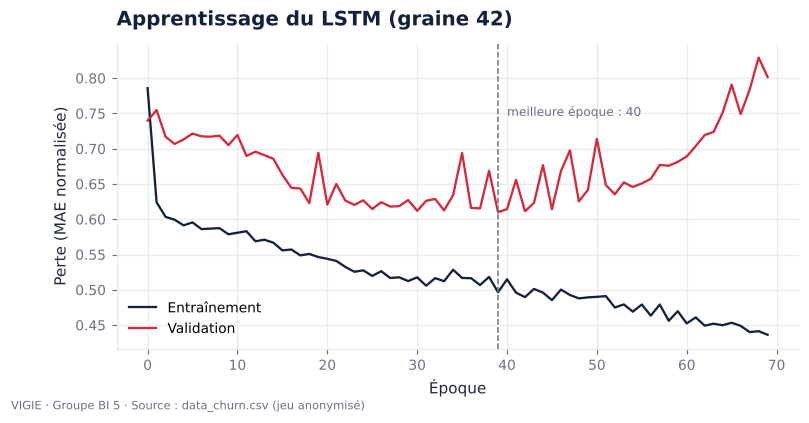

Époques effectuées avant arrêt précoce : {'LSTM': [70, 60, 64], 'RNN simple': [33, 56, 33]}


In [7]:
hist = resultat["historique_lstm"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(hist["loss"], color=C["encre"], label="Entraînement")
ax.plot(hist["val_loss"], color=C["churn"], label="Validation")
meilleure = int(np.argmin(hist["val_loss"]))
ax.axvline(meilleure, color=C["gris"], ls="--", lw=1)
ax.text(meilleure + 1, max(hist["loss"]) * 0.95, f"meilleure époque : {meilleure + 1}", fontsize=8, color=C["gris"])
ax.set_xlabel("Époque")
ax.set_ylabel("Perte (MAE normalisée)")
ax.set_title("Apprentissage du LSTM (graine 42)")
ax.legend()
style.enregistrer(fig, "04_lstm_apprentissage")
plt.show()
print("Époques effectuées avant arrêt précoce :", {m: comparaison.loc[m, "Époques"] for m in ["LSTM", "RNN simple"]})

Le LSTM a environ quatre fois plus de paramètres que le RNN simple (ses « portes » lui permettent de retenir ou
d'oublier une information sur plusieurs semaines). Dans les deux cas, il y a bien plus de paramètres que de fenêtres
d'entraînement : l'**arrêt précoce** est indispensable, et il intervient en effet après 60 à 70 époques pour le
LSTM, 33 à 56 pour le RNN.

## 4. Comparaison sur les 40 dernières semaines

**Métriques.** MAE (erreur absolue moyenne, en nombre de clôtures) et RMSE (qui pénalise davantage les grosses
erreurs). Le **MAPE n'est pas utilisé** : il n'est pas défini quand la valeur réelle vaut zéro.

In [8]:
naive = comparaison.loc["Naïve (dernière valeur)"]
tableau = comparaison[["Type", "MAE", "RMSE"]].copy()
tableau["MAE vs naïve"] = tableau["MAE"] / naive["MAE"] - 1
tableau["RMSE vs naïve"] = tableau["RMSE"] / naive["RMSE"] - 1
tableau["Dispersion MAE (3 graines)"] = comparaison.get("MAE écart-type")
tableau = tableau.sort_values("MAE")
display(tableau.style.format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "MAE vs naïve": "{:+.0%}", "RMSE vs naïve": "{:+.0%}",
                              "Dispersion MAE (3 graines)": lambda v: "—" if pd.isna(v) else f"± {v:.1f}"}))
print(tableau.round(3).to_string())

,Type,MAE,RMSE,MAE vs naïve,RMSE vs naïve,Dispersion MAE (3 graines)
Modèle,,,,,,
Médiane mobile 8 semaines,Référence,272.4,549.8,-43%,-36%,—
LSTM,Deep Learning,287.2,577.2,-40%,-33%,± 6.4
RNN simple,Deep Learning,323.6,607.7,-32%,-29%,± 9.3
"ARIMA(2, 1, 2)",Référence,334.7,576.7,-30%,-33%,—
Moyenne mobile 4 semaines,Référence,373.0,575.3,-22%,-33%,—
Naïve (dernière valeur),Référence,478.3,859.5,+0%,+0%,—


                                    Type      MAE     RMSE  MAE vs naïve  RMSE vs naïve  Dispersion MAE (3 graines)
Modèle                                                                                                             
Médiane mobile 8 semaines      Référence  272.400  549.767        -0.430         -0.360                         NaN
LSTM                       Deep Learning  287.185  577.250        -0.400         -0.328                       6.423
RNN simple                 Deep Learning  323.605  607.651        -0.323         -0.293                       9.285
ARIMA(2, 1, 2)                 Référence  334.709  576.710        -0.300         -0.329                         NaN
Moyenne mobile 4 semaines      Référence  373.031  575.338        -0.220         -0.331                         NaN
Naïve (dernière valeur)        Référence  478.300  859.478         0.000          0.000                         NaN


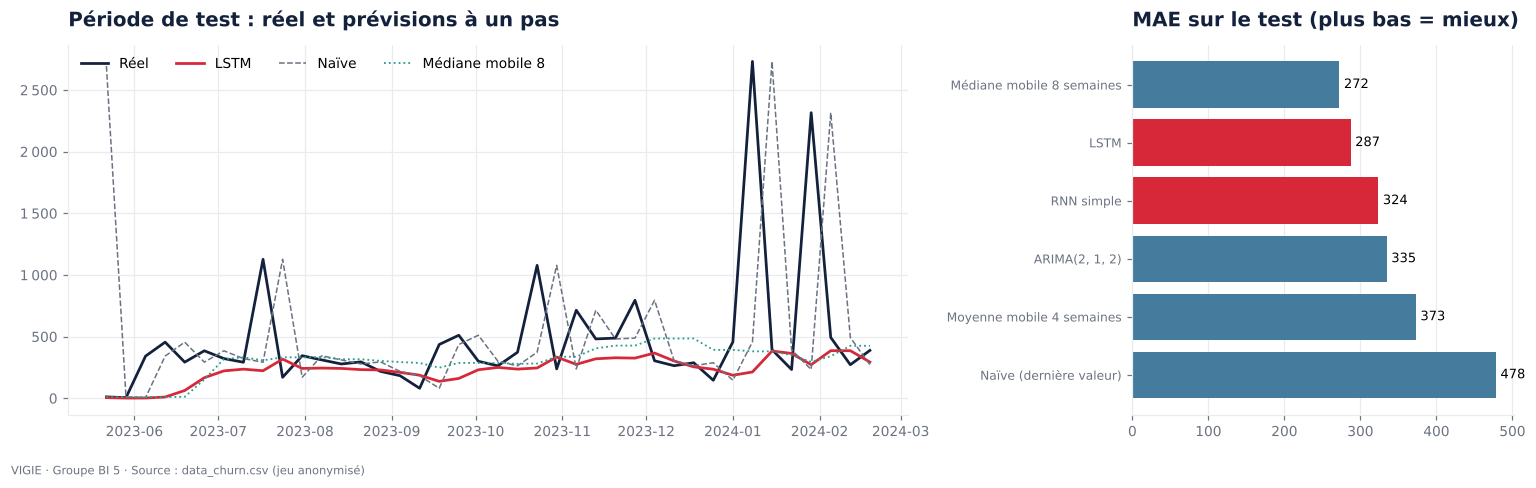

In [9]:
semaines_test = pd.to_datetime(resultat["test"]["semaines"])
reel = np.array(resultat["test"]["reel"])
prev = resultat["test"]["previsions"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(semaines_test, reel, color=C["encre"], lw=1.8, label="Réel")
axes[0].plot(semaines_test, prev["LSTM"], color=C["churn"], lw=1.8, label="LSTM")
axes[0].plot(semaines_test, prev["Naïve (dernière valeur)"], color=C["gris"], lw=1, ls="--", label="Naïve")
axes[0].plot(semaines_test, prev["Médiane mobile 8 semaines"], color=C["retention"], lw=1.2, ls=":", label="Médiane mobile 8")
axes[0].yaxis.set_major_formatter(style.milliers)
axes[0].set_title("Période de test : réel et prévisions à un pas")
axes[0].legend(ncol=4, loc="upper left")
ordre = tableau.index[::-1]
couleurs = [C["churn"] if comparaison.loc[m, "Type"] == "Deep Learning" else C["ciel"] for m in ordre]
axes[1].barh(ordre, tableau.loc[ordre, "MAE"], color=couleurs)
for i, m in enumerate(ordre):
    axes[1].text(tableau.loc[m, "MAE"] + 6, i, f"{tableau.loc[m, 'MAE']:.0f}", va="center", fontsize=8.5)
axes[1].set_title("MAE sur le test (plus bas = mieux)")
axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout()
style.enregistrer(fig, "04_lstm_vs_references")
plt.show()

**Lecture — le LSTM prouve-t-il son intérêt ?**

* **Face à la prévision naïve : oui, nettement.** Le LSTM réduit la MAE de 40 % (287 contre 478 clôtures) et la
  RMSE de 33 %. Répéter la dernière valeur est une mauvaise stratégie sur une série aussi irrégulière.
* **Face aux autres modèles : il est dans le haut du tableau.** Il fait mieux en MAE que le RNN simple (324),
  qu'ARIMA (335) et que la moyenne mobile (373). En RMSE, LSTM, ARIMA et moyenne mobile sont à égalité (≈ 576).
* **Face à la meilleure règle simple : non.** La **médiane mobile sur 8 semaines** fait légèrement mieux
  (MAE 272, RMSE 550). L'écart en MAE (15 clôtures) dépasse la dispersion du LSTM entre graines (± 6) : il est
  petit, mais il est réel.

**Conclusion honnête.** Le LSTM apporte un gain important par rapport à la référence naïve, mais il **n'améliore
pas** une médiane mobile, qui tient en une ligne. Trois raisons l'expliquent :

1. **Peu de données** : 134 fenêtres d'entraînement pour 4 385 paramètres.
2. **Changement de régime** : le modèle apprend surtout sur les régimes 1 et 2 (dont deux ans de traitement par
   lots) et il est testé sur le régime 3, plus élevé. La série normalisée a une moyenne de +0,82 sur le test au
   lieu de 0.
3. **Pics imprévisibles** : ils ne dépendent pas du passé de la série ; une médiane les ignore par construction,
   ce qui est ici la meilleure réponse.

Ce résultat est conforme à ce qu'annonçait le guide du projet : *avec environ 200 points, le LSTM peut ne pas
gagner, et ce résultat est acceptable s'il est démontré.*

## 5. Analyse des erreurs du LSTM

,Semaines,MAE du LSTM,MAE de la naïve,MAE de la médiane mobile 8,Erreur moyenne du LSTM (biais)
Semaines ordinaires (< 1 000),36,141.8,367.6,136.3,96.0
Semaines de pic (≥ 1 000),4,1574.8,1474.5,1496.9,1574.8
Ensemble du test,40,285.1,478.3,272.4,243.9


Part de l'erreur absolue totale due aux 4 semaines de pic : 55%


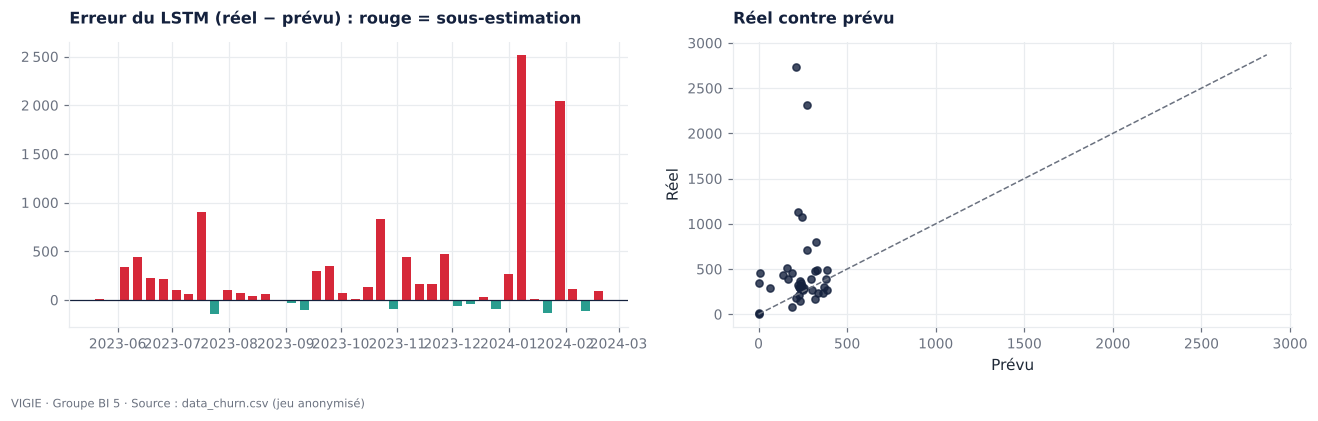

In [10]:
erreur = reel - np.array(prev["LSTM"])
pics = reel >= 1000
analyse = pd.DataFrame({
    "Semaines": [int((~pics).sum()), int(pics.sum()), len(reel)],
    "MAE du LSTM": [np.abs(erreur[~pics]).mean(), np.abs(erreur[pics]).mean(), np.abs(erreur).mean()],
    "MAE de la naïve": [np.abs(reel - np.array(prev["Naïve (dernière valeur)"]))[m].mean() for m in (~pics, pics, slice(None))],
    "MAE de la médiane mobile 8": [np.abs(reel - np.array(prev["Médiane mobile 8 semaines"]))[m].mean() for m in (~pics, pics, slice(None))],
    "Erreur moyenne du LSTM (biais)": [erreur[~pics].mean(), erreur[pics].mean(), erreur.mean()],
}, index=["Semaines ordinaires (< 1 000)", "Semaines de pic (≥ 1 000)", "Ensemble du test"])
display(analyse.round(1))
print(f"Part de l'erreur absolue totale due aux {int(pics.sum())} semaines de pic : {np.abs(erreur[pics]).sum() / np.abs(erreur).sum():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(semaines_test, erreur, width=5, color=[C["churn"] if e > 0 else C["retention"] for e in erreur])
axes[0].axhline(0, color=C["encre"], lw=0.8)
axes[0].set_title("Erreur du LSTM (réel − prévu) : rouge = sous-estimation", fontsize=10.5)
axes[0].yaxis.set_major_formatter(style.milliers)
axes[1].scatter(prev["LSTM"], reel, color=C["encre"], s=22, alpha=0.8)
lim = max(reel.max(), max(prev["LSTM"])) * 1.05
axes[1].plot([0, lim], [0, lim], color=C["gris"], ls="--", lw=1)
axes[1].set_xlabel("Prévu")
axes[1].set_ylabel("Réel")
axes[1].set_title("Réel contre prévu", fontsize=10.5)
fig.tight_layout()
style.enregistrer(fig, "04_lstm_erreurs")
plt.show()

**Lecture — où le LSTM se trompe.**

* **Quatre semaines de pic concentrent 55 % de l'erreur.** Sur ces semaines, aucun modèle ne fait mieux que les
  autres : l'erreur est d'environ 1 500 clôtures pour tous.
* **Sur les 36 semaines ordinaires, l'erreur du LSTM tombe à 142 clôtures**, contre 368 pour la naïve — soit
  2,6 fois moins — et 136 pour la médiane mobile.
* **Le LSTM sous-estime** : son erreur moyenne est positive (+96 sur les semaines ordinaires). C'est la trace du
  changement de régime : il a appris un niveau plus bas que celui de la période de test.

## 6. Prévision des 8 prochaines semaines

Au-delà de la dernière semaine observée, la prévision est **récursive** : chaque semaine prévue est réinjectée
comme entrée pour prévoir la suivante. L'incertitude augmente donc avec l'horizon.

L'intervalle affiché est **empirique** : il reprend les quantiles 10 % et 90 % de l'écart entre réel et prévu
observé sur la période de test. Il indique un ordre de grandeur de l'incertitude, pas une garantie statistique.

,Prévision LSTM,Borne basse (10 %),Borne haute (90 %)
semaines,,,
26/02/2024,276,193,1468
04/03/2024,245,171,1306
11/03/2024,223,156,1187
18/03/2024,205,143,1089
25/03/2024,190,132,1010
01/04/2024,179,125,953
08/04/2024,170,118,904
15/04/2024,162,113,861


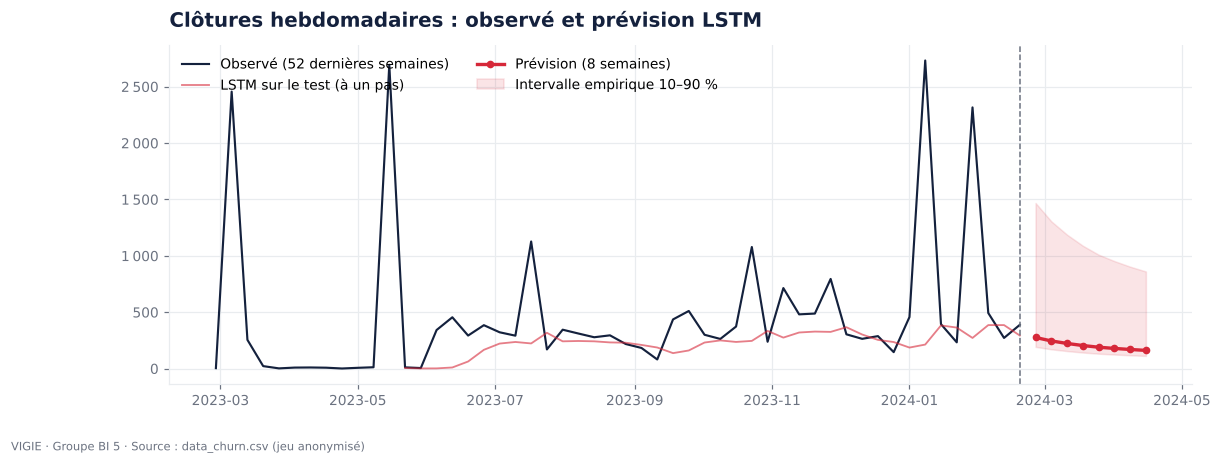

In [11]:
futur = pd.DataFrame(resultat["futur"]).set_index("semaines")
futur.index = pd.to_datetime(futur.index).strftime("%d/%m/%Y")
futur.columns = ["Prévision LSTM", "Borne basse (10 %)", "Borne haute (90 %)"]
display(futur.round(0).astype(int))

sem_futur = pd.to_datetime(resultat["futur"]["semaines"])
fig, ax = plt.subplots(figsize=(12, 4))
recent = serie.iloc[-52:]
ax.plot(recent.index, recent.values, color=C["encre"], lw=1.4, label="Observé (52 dernières semaines)")
ax.plot(semaines_test, prev["LSTM"], color=C["churn"], lw=1.2, alpha=0.6, label="LSTM sur le test (à un pas)")
ax.plot(sem_futur, resultat["futur"]["prevision"], color=C["churn"], lw=2.2, marker="o", ms=4, label="Prévision (8 semaines)")
ax.fill_between(sem_futur, resultat["futur"]["bas"], resultat["futur"]["haut"], color=C["churn"], alpha=0.12, label="Intervalle empirique 10–90 %")
ax.axvline(serie.index[-1], color=C["gris"], ls="--", lw=1)
ax.yaxis.set_major_formatter(style.milliers)
ax.set_title("Clôtures hebdomadaires : observé et prévision LSTM")
ax.legend(loc="upper left", ncol=2)
style.enregistrer(fig, "04_prevision_future")
plt.show()

**Lecture.** La prévision part d'environ 280 clôtures puis **décroît de semaine en semaine**. Ce n'est pas l'annonce
d'une baisse du churn : en mode récursif, le réseau se nourrit de ses propres prévisions et revient vers le niveau
moyen qu'il a appris. La prévision est donc utile surtout pour **la ou les deux premières semaines** ; au-delà,
elle doit être recalculée chaque semaine avec les nouvelles observations. La borne haute, très large, rappelle
qu'un pic reste possible à tout moment.

## 7. Bonus — un second KPI : les clients perdus par semaine

**Définition.** Nombre de clients dont le *dernier* compte se ferme dans la semaine : c'est le moment où le
client est définitivement perdu. Le premier KPI compte des comptes, celui-ci compte des **clients**.

La même démarche est appliquée sans rien changer au code : même règle pour les opérations de masse, même
découpage, mêmes modèles.

In [12]:
clients = donnees.grain_client(df, comptes)
brute_clients = series.serie_hebdo(clients.loc[clients["CHURN"] == 1, "DATE_CHURN"])
masse_clients = series.semaines_de_masse(brute_clients)
serie_clients = series.corriger_masse(brute_clients, masse_clients)
print(f"{len(serie_clients)} semaines · {fr(brute_clients.sum())} clients perdus · "
      f"{len(masse_clients)} semaines de masse ({brute_clients[masse_clients].sum() / brute_clients.sum():.1%} du volume) · "
      f"{int((serie_clients == 0).sum())} semaines à zéro")

resultat_clients = prevision.evaluer_kpi(serie_clients)
resultat_clients.pop("_modele_lstm")
comparaison_clients = pd.DataFrame(resultat_clients["comparaison"]).set_index("Modèle")
naive_c = comparaison_clients.loc["Naïve (dernière valeur)"]
tableau_clients = comparaison_clients[["Type", "MAE", "RMSE"]].copy()
tableau_clients["MAE vs naïve"] = tableau_clients["MAE"] / naive_c["MAE"] - 1
tableau_clients["RMSE vs naïve"] = tableau_clients["RMSE"] / naive_c["RMSE"] - 1
tableau_clients = tableau_clients.sort_values("MAE")
print(tableau_clients.round(3).to_string())

202 semaines · 117 345 clients perdus · 4 semaines de masse (55.2% du volume) · 13 semaines à zéro


                                    Type      MAE     RMSE  MAE vs naïve  RMSE vs naïve
Modèle                                                                                 
LSTM                       Deep Learning  124.501  220.184        -0.452         -0.521
Médiane mobile 8 semaines      Référence  133.300  216.366        -0.413         -0.529
RNN simple                 Deep Learning  143.630  232.844        -0.368         -0.493
ARIMA(2, 1, 2)                 Référence  159.884  248.945        -0.296         -0.458
Moyenne mobile 4 semaines      Référence  196.419  275.980        -0.135         -0.399
Naïve (dernière valeur)        Référence  227.200  459.468         0.000          0.000


**Lecture — second KPI.** La même démarche donne des conclusions voisines, avec une nuance favorable au réseau :
sur les clients perdus, le **LSTM a la meilleure MAE** (125 contre 133 pour la médiane mobile) et la deuxième
RMSE (220 contre 216). Il réduit la MAE de 45 % par rapport à la naïve. La série « clients » est un peu plus
régulière que la série « comptes », ce qui profite au modèle appris.

## Synthèse

| KPI | Meilleure MAE | LSTM vs naïve (MAE) | LSTM vs meilleure référence simple (MAE) |
|---|---|---|---|
| Clôtures de comptes par semaine | Médiane mobile 8 (272) | −40 % | +5 % (287 contre 272) |
| Clients perdus par semaine | **LSTM (125)** | −45 % | −7 % (125 contre 133) |

**Ce que nous retenons pour l'application.** La prévision affichée est celle du **LSTM**, comme demandé, accompagnée
du tableau comparatif complet : l'utilisateur voit la prévision *et* son niveau de fiabilité par rapport à des règles
simples. En exploitation, nous recommanderions de suivre le LSTM et la médiane mobile côte à côte, et de
ré-entraîner le réseau à mesure que le régime actuel s'allonge.

In [13]:
# Enregistrement des résultats (agrégats hebdomadaires et métriques : aucune donnée individuelle).
def nettoyer(r: dict) -> dict:
    return {k: v for k, v in r.items() if k != "historique_lstm"}


config.RESULTATS_ML.mkdir(parents=True, exist_ok=True)
(config.RESULTATS_ML / "prevision_kpi.json").write_text(json.dumps({
    "source_sha256": donnees.empreinte()["sha256"],
    "clotures_hebdo": nettoyer(resultat),
    "clients_perdus_hebdo": nettoyer(resultat_clients),
}, ensure_ascii=False, indent=1), encoding="utf-8")

# Artefact lu par l'application : la série, la prévision et la comparaison des modèles.
config.ARTEFACTS_APP.mkdir(parents=True, exist_ok=True)
(config.ARTEFACTS_APP / "prevision_kpi.json").write_text(json.dumps({
    "kpi": "Nombre hebdomadaire de clôtures de comptes",
    "note_dates": "Dates décalées par l'anonymisation : lire des durées et des évolutions, pas un calendrier réel.",
    "historique": {"semaines": [str(s.date()) for s in serie.index], "brute": [int(v) for v in brute.values],
                   "corrigee": [int(v) for v in serie.values], "semaines_de_masse": [str(s.date()) for s in masse]},
    "decoupage": resultat["decoupage"],
    "test": resultat["test"],
    "futur": resultat["futur"],
    "comparaison": [{k: v for k, v in ligne.items() if k != "Époques"} for ligne in resultat["comparaison"]],
    "second_kpi": {"nom": "Clients perdus par semaine",
                   "comparaison": [{k: v for k, v in ligne.items() if k != "Époques"} for ligne in resultat_clients["comparaison"]]},
}, ensure_ascii=False, indent=1), encoding="utf-8")

# Le modèle entraîné reste hors du dépôt (dossier ignoré par git).
config.MODELES.mkdir(parents=True, exist_ok=True)
modele_lstm.save(config.MODELES / "lstm_clotures_hebdo.keras")
print("Résultats : 04_machine_learning/resultats/prevision_kpi.json")
print("Artefact  : 05_web_app/artifacts/prevision_kpi.json")
print("Modèle    : 04_machine_learning/models/lstm_clotures_hebdo.keras (hors dépôt)")

Résultats : 04_machine_learning/resultats/prevision_kpi.json
Artefact  : 05_web_app/artifacts/prevision_kpi.json
Modèle    : 04_machine_learning/models/lstm_clotures_hebdo.keras (hors dépôt)
